# Cloud Removal — Best Model Prediction Notebook
Independent inference notebook. It uses **only** the saved best model in `models/best_model/` and its saved preprocessing configuration. No training and no other models are used.

**Input:** a Sentinel-1 GeoTIFF (VV, VH in dB) and a cloudy Sentinel-2 L1C GeoTIFF (13 bands, DN), both 256×256 and co-registered.
**Output:** a cloud-free 13-band Sentinel-2 image (GeoTIFF) + per-pixel uncertainty map.

## 1. Import Required Libraries
Imports the libraries needed for reading rasters, preprocessing and running the TorchScript model.

In [1]:
import os, json, glob
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt
from scipy import ndimage, signal
import torch
import warnings; warnings.filterwarnings("ignore", category=FutureWarning)

## 2. Define Paths
Points to the best-model folder, the raw data folder (for the sample input) and an output folder for predictions.

In [2]:
ROOT = os.path.abspath("..")
BEST_DIR = os.path.join(ROOT, "models", "best_model")
RAW_DIR = os.path.join(ROOT, "data", "raw", "sen12mscr_style")
OUT_DIR = os.path.join(ROOT, "data", "processed", "predictions"); os.makedirs(OUT_DIR, exist_ok=True)
print(sorted(os.listdir(BEST_DIR)))

['best_model_config.json', 'best_model_state_dict.pth', 'best_model_torchscript.pt', 'preprocessing.json']


## 3. Load Best-Model Configuration and Preprocessing Settings
Reads the saved model description, test metrics and the exact preprocessing parameters used during training.

In [3]:
cfg = json.load(open(os.path.join(BEST_DIR, "best_model_config.json")))
PREPROC = json.load(open(os.path.join(BEST_DIR, "preprocessing.json")))
print("Best model:", cfg["display_name"]); print("Test metrics:", {k: round(v, 4) for k, v in cfg["test_metrics"].items() if isinstance(v, (int, float))})
print("Preprocessing:", json.dumps({k: PREPROC[k] for k in ("s1_clip_db", "s2_clip", "cloud_threshold", "patch_size")}))

Best model: PSF-CR (paper)
Test metrics: {'PSNR': 30.0822, 'SSIM': 0.8635, 'SAM': 8.4417, 'MAE': 0.0245, 'Params (M)': 3.2971, 'Inference (ms/img)': 852.0819}
Preprocessing: {"s1_clip_db": {"VV": [-25.0, 0.0], "VH": [-32.5, 0.0]}, "s2_clip": [0.0, 10000.0], "cloud_threshold": 0.2, "patch_size": 256}


## 4. Load the Best Model
Loads the self-contained TorchScript export of the best model on CPU (or GPU if available).

In [4]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = torch.jit.load(os.path.join(BEST_DIR, "best_model_torchscript.pt"), map_location=DEVICE).eval()
print("loaded", type(model).__name__, "on", DEVICE)

loaded RecursiveScriptModule on cpu


## 5. Define the Rule-Based Cloud Detector
Re-creates the cloud mask exactly as in training, using the thresholds stored in `preprocessing.json`.

In [5]:
def cloud_score(dn, cfg=PREPROC):
    d = dn.astype("float32") / 10000.0
    r = lambda x, lo_hi: (x - lo_hi[0]) / (lo_hi[1] - lo_hi[0])
    R = cfg["cloud_rules"]; s = np.ones(d.shape[1:], "float32")
    s = np.minimum(s, r(d[1], R["B02"])); s = np.minimum(s, r(d[0], R["B01"]))
    s = np.minimum(s, r(d[0] + d[10], R["B01+B10"])); s = np.minimum(s, r(d[3] + d[2] + d[1], R["B02+B03+B04"]))
    ndsi = (d[2] - d[11]) / (d[2] + d[11] + 1e-6); s = np.minimum(s, r(ndsi, R["NDSI(B03,B11)"]))
    k, b = cfg["cloud_closing_size"], cfg["cloud_box_size"]
    s = ndimage.grey_closing(s, size=(k, k)); s = signal.convolve2d(s, np.ones((b, b)) / b ** 2, mode="same")
    return np.clip(s, 1e-5, 1.0)

## 6. Define the Preprocessing Function
Same normalisation as training: SAR clipped to the stored dB ranges and scaled to [0,1]; Sentinel-2 clipped to [0,10000] and scaled to [0,1]; binary cloud mask.

In [6]:
def preprocess(s1_db, s2_cloudy_dn, cfg=PREPROC):
    lo = np.array([cfg["s1_clip_db"][b][0] for b in cfg["s1_bands"]], "float32")[:, None, None]
    hi = np.array([cfg["s1_clip_db"][b][1] for b in cfg["s1_bands"]], "float32")[:, None, None]
    sar = (np.clip(s1_db, lo, hi) - lo) / (hi - lo)
    a, b = cfg["s2_clip"]
    opt = (np.clip(s2_cloudy_dn.astype("float32"), a, b) - a) / (b - a)
    mask = (cloud_score(s2_cloudy_dn, cfg) >= cfg["cloud_threshold"]).astype("float32")[None]
    return sar.astype("float32"), opt.astype("float32"), mask

## 7. Define the Input Reader with Validation
Reads the two GeoTIFFs and checks band count, size and georeferencing before prediction.

In [7]:
def read_inputs(s1_path, s2_cloudy_path):
    with rasterio.open(s1_path) as a, rasterio.open(s2_cloudy_path) as b:
        s1, s2, prof = a.read().astype("float32"), b.read(), b.profile
        assert a.count == 2 and b.count == 13, "expected S1 with 2 bands (VV,VH dB) and S2 with 13 bands"
        assert a.shape == b.shape == tuple(cfg["input_size"]), f"expected {cfg['input_size']} pixels"
        assert a.crs == b.crs and a.transform == b.transform, "S1 and S2 must be co-registered"
    assert np.isfinite(s1).all(), "S1 contains NaN/Inf"
    return s1, s2, prof

## 8. Define the Prediction Function
Runs the model with test-time augmentation (4 rotations × flip); the mean is the prediction and the per-pixel standard deviation is reported as an uncertainty / confidence measure.

In [8]:
@torch.no_grad()
def predict(sar, opt, mask, tta=True):
    x = [torch.from_numpy(v)[None].to(DEVICE) for v in (sar, opt, mask)]
    outs = []
    for k in (range(4) if tta else [0]):
        for flip in ((False, True) if tta else (False,)):
            t = [torch.rot90(v, k, (2, 3)) for v in x]; t = [v.flip(3) for v in t] if flip else t
            y = model(*t)
            y = y.flip(3) if flip else y; outs.append(torch.rot90(y, -k, (2, 3)))
    outs = torch.stack(outs)
    return outs.mean(0)[0].cpu().numpy(), outs.std(0)[0].mean(0).cpu().numpy()

## 9. Select the Sample Input
Picks a sample S1 / cloudy S2 pair from the held-out test ROIs (the cloud-free image is used only afterwards to check the result).

In [9]:
test_index = pd.read_csv(os.path.join(ROOT, "data", "processed", "test_index.csv"))
sample = test_index.sort_values("cloud_frac").iloc[len(test_index) * 2 // 3]
S1_PATH = os.path.join(RAW_DIR, "s1", sample.patch + ".tif")
S2_CLOUDY_PATH = os.path.join(RAW_DIR, "s2_cloudy", sample.patch + ".tif")
S2_REFERENCE_PATH = os.path.join(RAW_DIR, "s2", sample.patch + ".tif")   # optional ground truth
print(sample[["patch", "roi", "tile", "cloudy_date", "clear_date", "cloud_frac", "lon", "lat"]].to_string())

patch          20190109T101238_19MFR_20190110_p3608
roi                                 20190109T101238
tile                                          19MFR
cloudy_date                                20190110
clear_date                                 20190219
cloud_frac                                  0.50737
lon                                      -67.902535
lat                                       -4.463033


## 10. Read and Preprocess the Sample
Loads the sample rasters and applies the training preprocessing.

In [10]:
s1_db, s2_dn, profile = read_inputs(S1_PATH, S2_CLOUDY_PATH)
sar, opt, mask = preprocess(s1_db, s2_dn)
print("sar", sar.shape, sar.min().round(3), sar.max().round(3), "| opt", opt.shape, "| cloud cover", f"{mask.mean() * 100:.1f}%")

sar (2, 256, 256) 0.0 1.0 | opt (13, 256, 256) | cloud cover 50.7%


## 11. Generate the Prediction
Runs the best model on the preprocessed input.

In [11]:
pred, uncertainty = predict(sar, opt, mask)
print("prediction", pred.shape, f"range [{pred.min():.4f}, {pred.max():.4f}]")

prediction (13, 256, 256) range [0.0000, 0.3196]


## 12. Prediction Confidence
Converts the TTA spread into a confidence score (cloud removal is pixel regression, so no class probabilities exist).

In [12]:
conf_map = 1.0 - np.clip(uncertainty / 0.05, 0, 1)           # 1 = consistent across all 8 TTA views
m = mask[0] > 0.5
print(f"mean TTA std: {uncertainty.mean():.5f} (reflectance units)")
print(f"confidence  overall {conf_map.mean() * 100:.1f}% | under clouds {conf_map[m].mean() * 100 if m.any() else float('nan'):.1f}% | clear {conf_map[~m].mean() * 100 if (~m).any() else float('nan'):.1f}%")

mean TTA std: 0.00310 (reflectance units)
confidence  overall 93.8% | under clouds 93.7% | clear 94.0%


## 13. Visualise the Result
Displays SAR, cloudy input, cloud mask, predicted cloud-free image, uncertainty map and (if available) the reference.

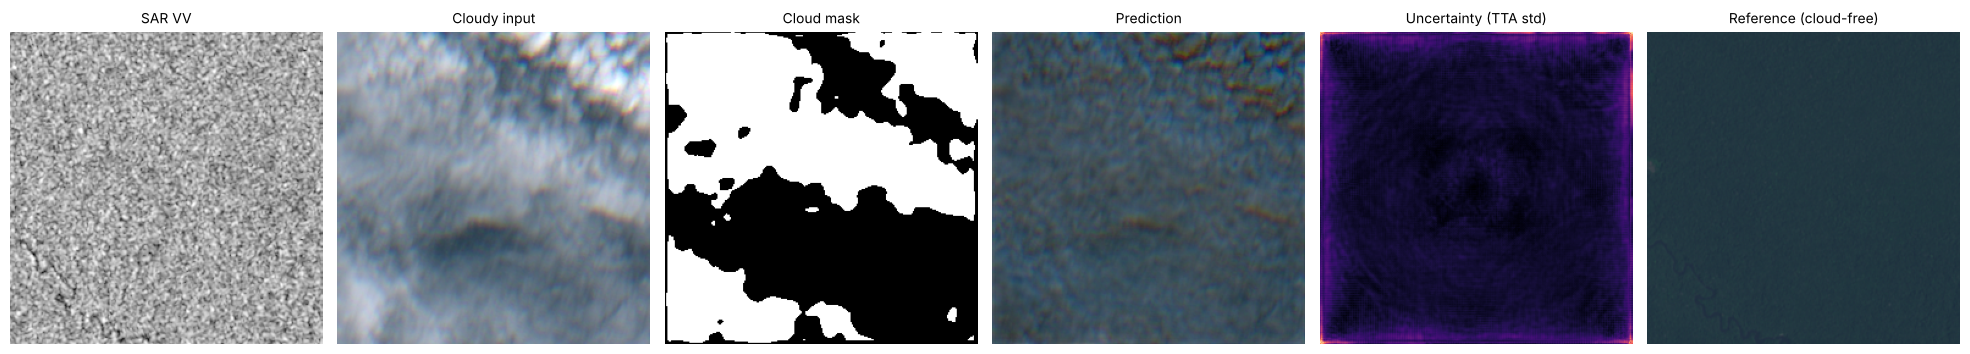

In [13]:
rgb = lambda x: np.clip(x[[3, 2, 1]].transpose(1, 2, 0) * 3.3, 0, 1)
panels = [(sar[0], "SAR VV", "gray"), (rgb(opt), "Cloudy input", None), (mask[0], "Cloud mask", "gray"), (rgb(pred), "Prediction", None), (uncertainty, "Uncertainty (TTA std)", "magma")]
ref = None
if os.path.exists(S2_REFERENCE_PATH):
    with rasterio.open(S2_REFERENCE_PATH) as r_: ref = np.clip(r_.read().astype("float32"), *PREPROC["s2_clip"]) / PREPROC["s2_clip"][1]
    panels.append((rgb(ref), "Reference (cloud-free)", None))
fig, ax = plt.subplots(1, len(panels), figsize=(3.3 * len(panels), 3.6))
for a, (im, t, cm) in zip(ax, panels): a.imshow(im, cmap=cm); a.set_title(t, fontsize=10); a.axis("off")
plt.tight_layout(); plt.show()

## 14. Check Against the Reference
If the cloud-free reference exists, computes PSNR, SAM and MAE of the cloudy input and of the prediction.

In [14]:
def metrics(p, t):
    mse = ((p - t) ** 2).mean(); cos = (p * t).sum(0) / (np.linalg.norm(p, axis=0) * np.linalg.norm(t, axis=0) + 1e-8)
    return {"PSNR": float(10 * np.log10(1 / mse)), "SAM": float(np.degrees(np.arccos(np.clip(cos, -1, 1))).mean()), "MAE": float(np.abs(p - t).mean())}
if ref is not None:
    print("cloudy input :", {k: round(v, 4) for k, v in metrics(opt, ref).items()})
    print("prediction   :", {k: round(v, 4) for k, v in metrics(pred, ref).items()})

cloudy input : {'PSNR': 21.114, 'SAM': 18.0483, 'MAE': 0.0744}
prediction   : {'PSNR': 29.7218, 'SAM': 12.0258, 'MAE': 0.0264}


## 15. Save the Prediction as GeoTIFF
Writes the cloud-free image (L1C DN scale, uint16) and the uncertainty map with the input's georeferencing.

In [15]:
out_path = os.path.join(OUT_DIR, f"{sample.patch}_cloudfree.tif")
prof = {**profile, "count": 13, "dtype": "uint16", "compress": "deflate"}
with rasterio.open(out_path, "w", **prof) as dst: dst.write(np.round(pred * PREPROC["s2_clip"][1]).astype("uint16"))
unc_path = os.path.join(OUT_DIR, f"{sample.patch}_uncertainty.tif")
with rasterio.open(unc_path, "w", **{**profile, "count": 1, "dtype": "float32", "compress": "deflate"}) as dst: dst.write(uncertainty[None].astype("float32"))
print(out_path); print(unc_path)

/home/claude/PROJECT_MAIN/data/processed/predictions/20190109T101238_19MFR_20190110_p3608_cloudfree.tif
/home/claude/PROJECT_MAIN/data/processed/predictions/20190109T101238_19MFR_20190110_p3608_uncertainty.tif


## 16. Prediction Summary
Prints a clear final summary of the prediction.

In [16]:
print("=" * 60)
print(f"Model            : {cfg['display_name']}")
print(f"Input patch      : {sample.patch}  (lon {sample.lon:.3f}, lat {sample.lat:.3f})")
print(f"Cloud cover      : {mask.mean() * 100:.1f}% of pixels reconstructed with SAR guidance")
print(f"Confidence       : {conf_map.mean() * 100:.1f}% (TTA consistency)")
if ref is not None: print(f"PSNR vs reference: {metrics(pred, ref)['PSNR']:.2f} dB (cloudy input: {metrics(opt, ref)['PSNR']:.2f} dB)")
print(f"Output GeoTIFF   : {os.path.relpath(out_path, ROOT)}")
print("=" * 60)

Model            : PSF-CR (paper)
Input patch      : 20190109T101238_19MFR_20190110_p3608  (lon -67.903, lat -4.463)
Cloud cover      : 50.7% of pixels reconstructed with SAR guidance
Confidence       : 93.8% (TTA consistency)
PSNR vs reference: 29.72 dB (cloudy input: 21.11 dB)
Output GeoTIFF   : data/processed/predictions/20190109T101238_19MFR_20190110_p3608_cloudfree.tif
